In [ ]:
!ls {dataset.location}
!cat {dataset.location}/data.yaml

In [ ]:
!nvidia-smi
!pip install ultralytics roboflow

Sat Nov 14 07:30:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!nvidia-smi
!pip install ultralytics roboflow

Sat Nov 14 07:31:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from roboflow import Roboflow
rf = Roboflow(api_key="*****")
project = rf.workspace("s-workspace-t693b").project("yolo-homework-l9hmw")
version = project.version(1)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to yolo-homework-1 in yolov8:: 100%|██████████| 798/798 [00:00<00:00, 7385.01it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
!ls {dataset.location}
!cat {dataset.location}/data.yaml

data.yaml  README.roboflow.txt	train
names:
- Lip_balm
- Sprayer
- action_figures
nc: 3
roboflow:
  license: Private
  project: yolo-homework-l9hmw
  url: https://app.roboflow.com/s-workspace-t693b/yolo-homework-l9hmw/1
  version: 1
  workspace: s-workspace-t693b
test: ../test/images
train: ../train/images
val: ../valid/images


In [ ]:
import yaml
from ultralytics import YOLO

yaml_path = f"{dataset.location}/data.yaml"
with open(yaml_path, 'r') as f:
    cfg = yaml.safe_load(f)

cfg['path'] = dataset.location
cfg['train'] = "train/images"
cfg['val'] = "valid/images"
cfg['test'] = "test/images"

with open(yaml_path, 'w') as f:
    yaml.dump(cfg, f)

model = YOLO("yolov8n.pt")
model.train(data=yaml_path, epochs=50, imgsz=640, batch=16)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo-homework-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=False,

RuntimeError: Dataset '/content/yolo-homework-1/data.yaml' error ❌ Dataset '/content/yolo-homework-1/data.yaml' images not found, missing path '/content/yolo-homework-1/valid/images'
Note dataset download directory is '/content/datasets'. You can update this in '/root/.config/Ultralytics/settings.json'

In [ ]:
!ls /content/yolo-homework-1
!cat /content/yolo-homework-1/data.yaml

data.yaml  README.roboflow.txt	train
names:
- Lip_balm
- Sprayer
- action_figures
nc: 3
path: /content/yolo-homework-1
roboflow:
  license: Private
  project: yolo-homework-l9hmw
  url: https://app.roboflow.com/s-workspace-t693b/yolo-homework-l9hmw/1
  version: 1
  workspace: s-workspace-t693b
test: test/images
train: train/images
val: valid/images


In [ ]:
import yaml
from ultralytics import YOLO

yaml_path = "/content/yolo-homework-1/data.yaml"
with open(yaml_path) as f:
    cfg = yaml.safe_load(f)

cfg['path'] = "/content/yolo-homework-1"
cfg['train'] = "train/images"
cfg['val'] = "val/images"      # 실제 폴더 이름에 맞게
cfg['test'] = "test/images"

with open(yaml_path, 'w') as f:
    yaml.dump(cfg, f)

model = YOLO("yolov8n.pt")
model.train(data=yaml_path, epochs=50, imgsz=640, batch=16)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo-homework-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-3, nbs=64, nms=None, opset=None, optimize=False,

RuntimeError: Dataset '/content/yolo-homework-1/data.yaml' error ❌ Dataset '/content/yolo-homework-1/data.yaml' images not found, missing path '/content/yolo-homework-1/val/images'
Note dataset download directory is '/content/datasets'. You can update this in '/root/.config/Ultralytics/settings.json'

In [ ]:
import yaml
from ultralytics import YOLO

yaml_path = "/content/yolo-homework-1/data.yaml"
with open(yaml_path) as f:
    cfg = yaml.safe_load(f)

cfg['path'] = "/content/yolo-homework-1"
cfg['train'] = "train/images"
cfg['val'] = "val/images"      # 실제 폴더 이름에 맞게
cfg['test'] = "test/images"

with open(yaml_path, 'w') as f:
    yaml.dump(cfg, f)

model = YOLO("yolov8n.pt")
model.train(data=yaml_path, epochs=50, imgsz=640, batch=16)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo-homework-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-4, nbs=64, nms=None, opset=None, optimize=False,

RuntimeError: Dataset '/content/yolo-homework-1/data.yaml' error ❌ Dataset '/content/yolo-homework-1/data.yaml' images not found, missing path '/content/yolo-homework-1/val/images'
Note dataset download directory is '/content/datasets'. You can update this in '/root/.config/Ultralytics/settings.json'

In [10]:
!ls {dataset.location}
!cat {dataset.location}/data.yaml

data.yaml  README.roboflow.txt	train
names:
- Lip_balm
- Sprayer
- action_figures
nc: 3
path: /content/yolo-homework-1
roboflow:
  license: Private
  project: yolo-homework-l9hmw
  url: https://app.roboflow.com/s-workspace-t693b/yolo-homework-l9hmw/1
  version: 1
  workspace: s-workspace-t693b
test: test/images
train: train/images
val: val/images


In [11]:
import os, random, shutil, glob

base = "/content/yolo-homework-1"
random.seed(0)

imgs = sorted(glob.glob(f"{base}/train/images/*"))
print("전체 train 사진 수:", len(imgs))

random.shuffle(imgs)
n_val = int(len(imgs) * 0.2)
val_imgs = imgs[:n_val]

os.makedirs(f"{base}/valid/images", exist_ok=True)
os.makedirs(f"{base}/valid/labels", exist_ok=True)

for p in val_imgs:
    name = os.path.splitext(os.path.basename(p))[0]
    shutil.move(p, f"{base}/valid/images/")
    lbl = f"{base}/train/labels/{name}.txt"
    if os.path.exists(lbl):
        shutil.move(lbl, f"{base}/valid/labels/")

# 이전 실패 때 생긴 캐시 파일 삭제
!rm -f {base}/train/labels.cache

print("train:", len(os.listdir(f"{base}/train/images")))
print("valid:", len(os.listdir(f"{base}/valid/images")))

전체 train 사진 수: 398
train: 319
valid: 79


In [12]:
import yaml

yaml_path = f"{base}/data.yaml"
with open(yaml_path) as f:
    cfg = yaml.safe_load(f)

cfg['path'] = base
cfg['train'] = "train/images"
cfg['val'] = "valid/images"
cfg.pop('test', None)

with open(yaml_path, 'w') as f:
    yaml.dump(cfg, f)

!cat {yaml_path}

names:
- Lip_balm
- Sprayer
- action_figures
nc: 3
path: /content/yolo-homework-1
roboflow:
  license: Private
  project: yolo-homework-l9hmw
  url: https://app.roboflow.com/s-workspace-t693b/yolo-homework-l9hmw/1
  version: 1
  workspace: s-workspace-t693b
train: train/images
val: valid/images


In [13]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")
model.train(data=yaml_path, epochs=50, imgsz=640, batch=16)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo-homework-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-5, nbs=64, nms=None, opset=None, optimize=False,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f51c89d8b40>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [14]:
!ls /content/runs/detectrain-5$0

train  train-2	train-3  train-4  train-5


In [15]:
!ls /content/runs/detect/train*/weights

/content/runs/detect/train-2/weights:

/content/runs/detect/train-3/weights:

/content/runs/detect/train-4/weights:

/content/runs/detect/train-5/weights:
best.pt  last.pt

/content/runs/detect/train/weights:


In [16]:
from ultralytics import YOLO

model = YOLO("/content/runs/detect/train-5/weights/best.pt")
metrics = model.val()
print("mAP50    :", metrics.box.map50)
print("mAP50-95 :", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall   :", metrics.box.mr)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 991.7±288.2 MB/s, size: 22.3 KB)
val: Scanning /content/yolo-homework-1/valid/labels.cache... 79 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 79/79 25.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.8it/s 2.7s
                   all         79        119      0.999       0.99      0.995       0.97
              Lip_balm         49         49      0.998       0.98      0.995      0.948
               Sprayer         35         35          1      0.992      0.995      0.986
        action_figures         35         35      0.998          1      0.995      0.977
Speed: 5.1ms preprocess, 6.7ms inference, 0.0ms loss, 4.3ms postprocess per image
Results saved to /content/runs/detect/val
mAP50    : 

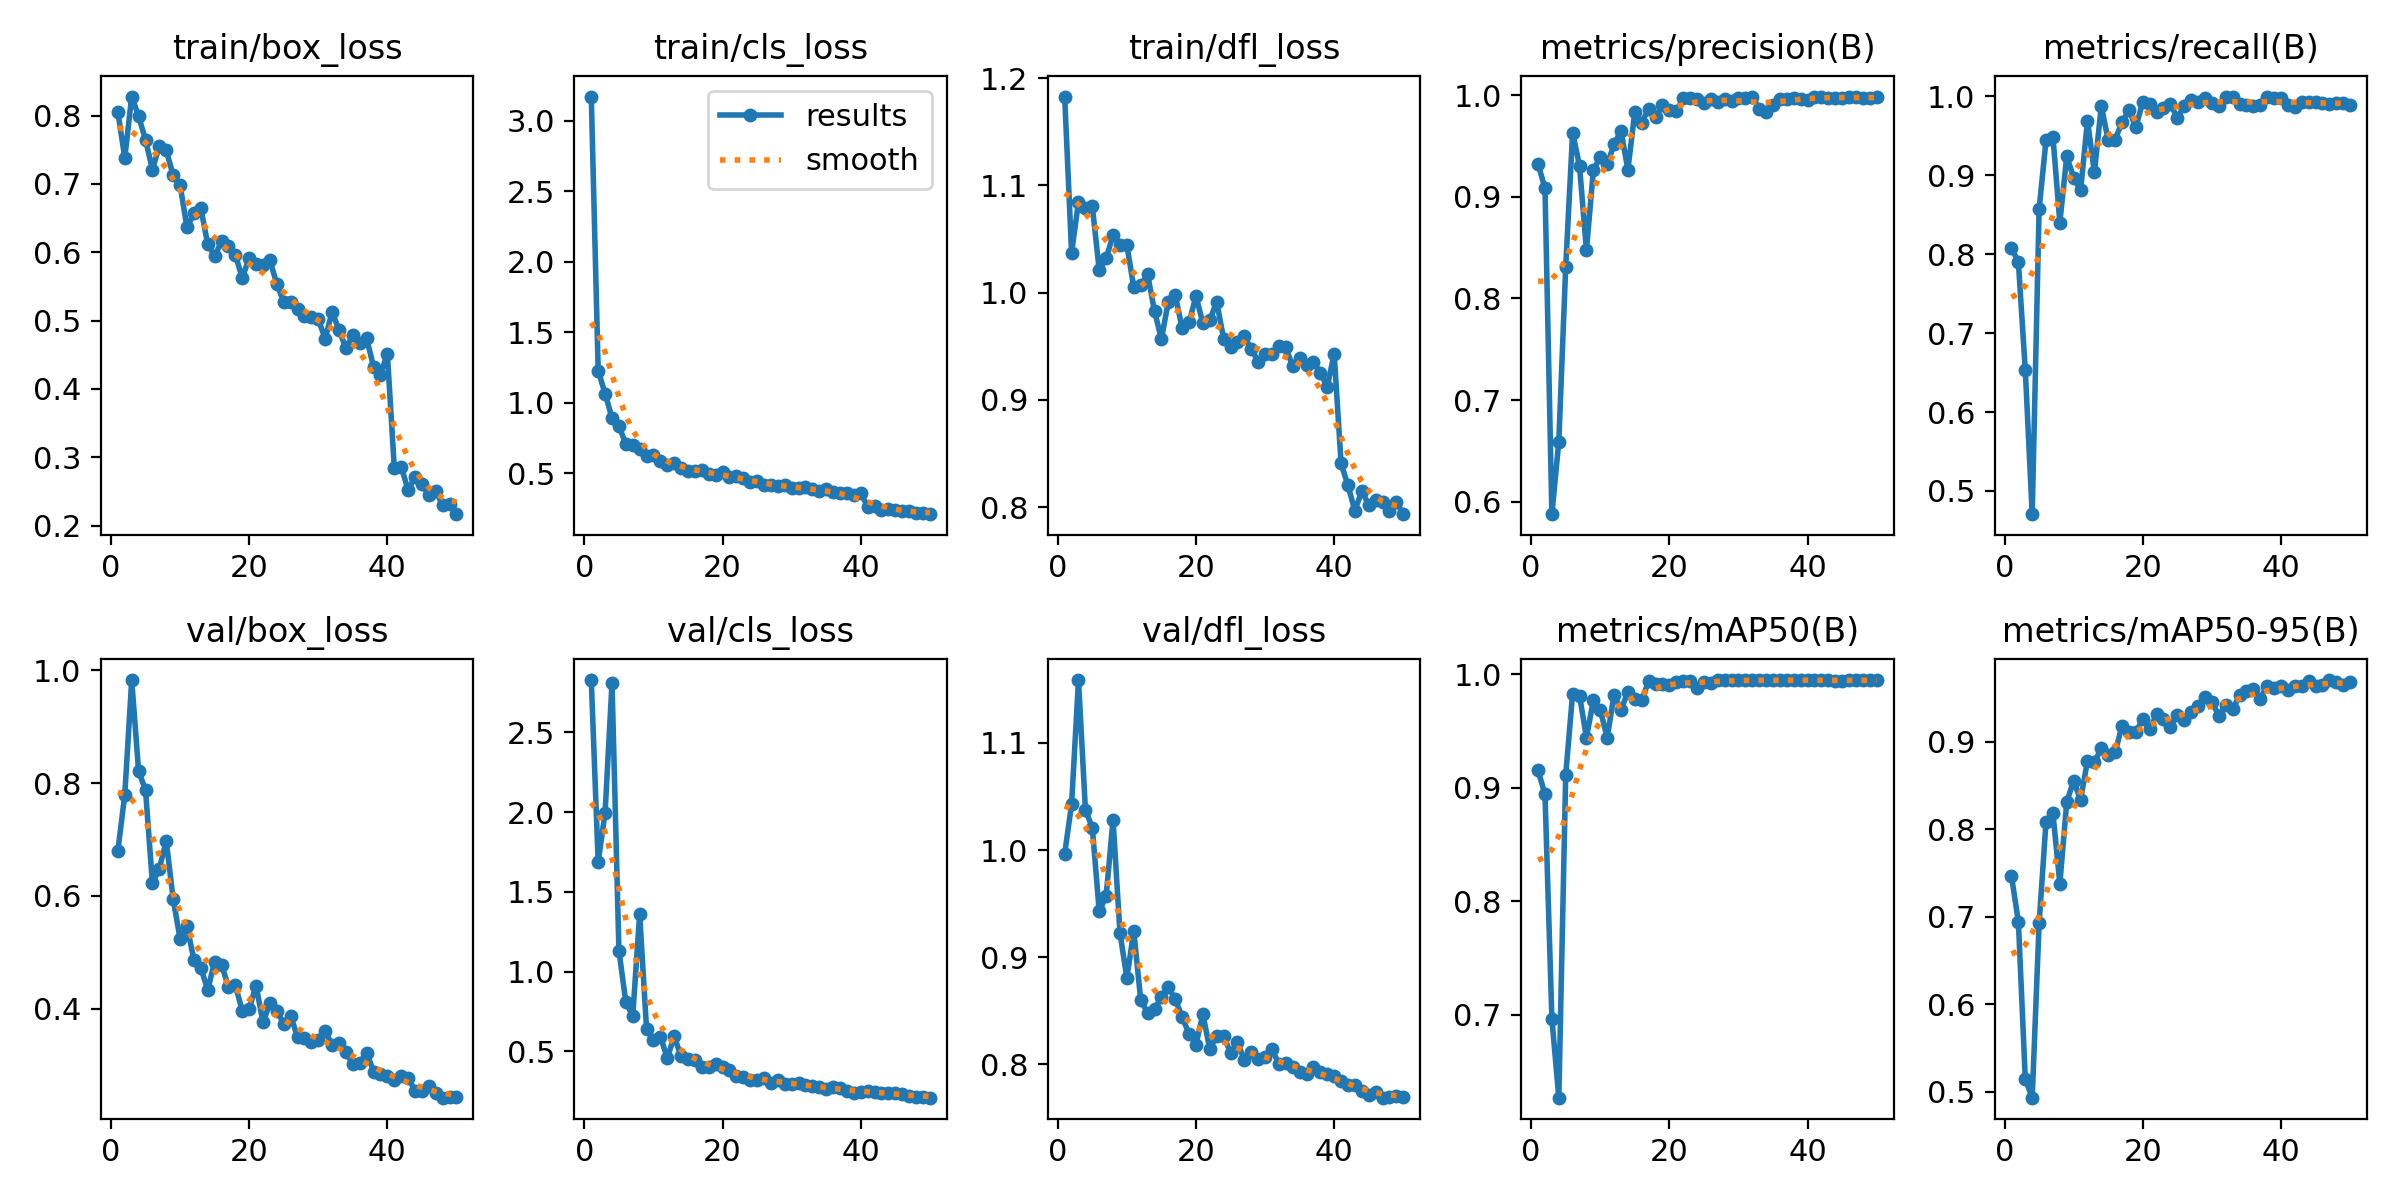

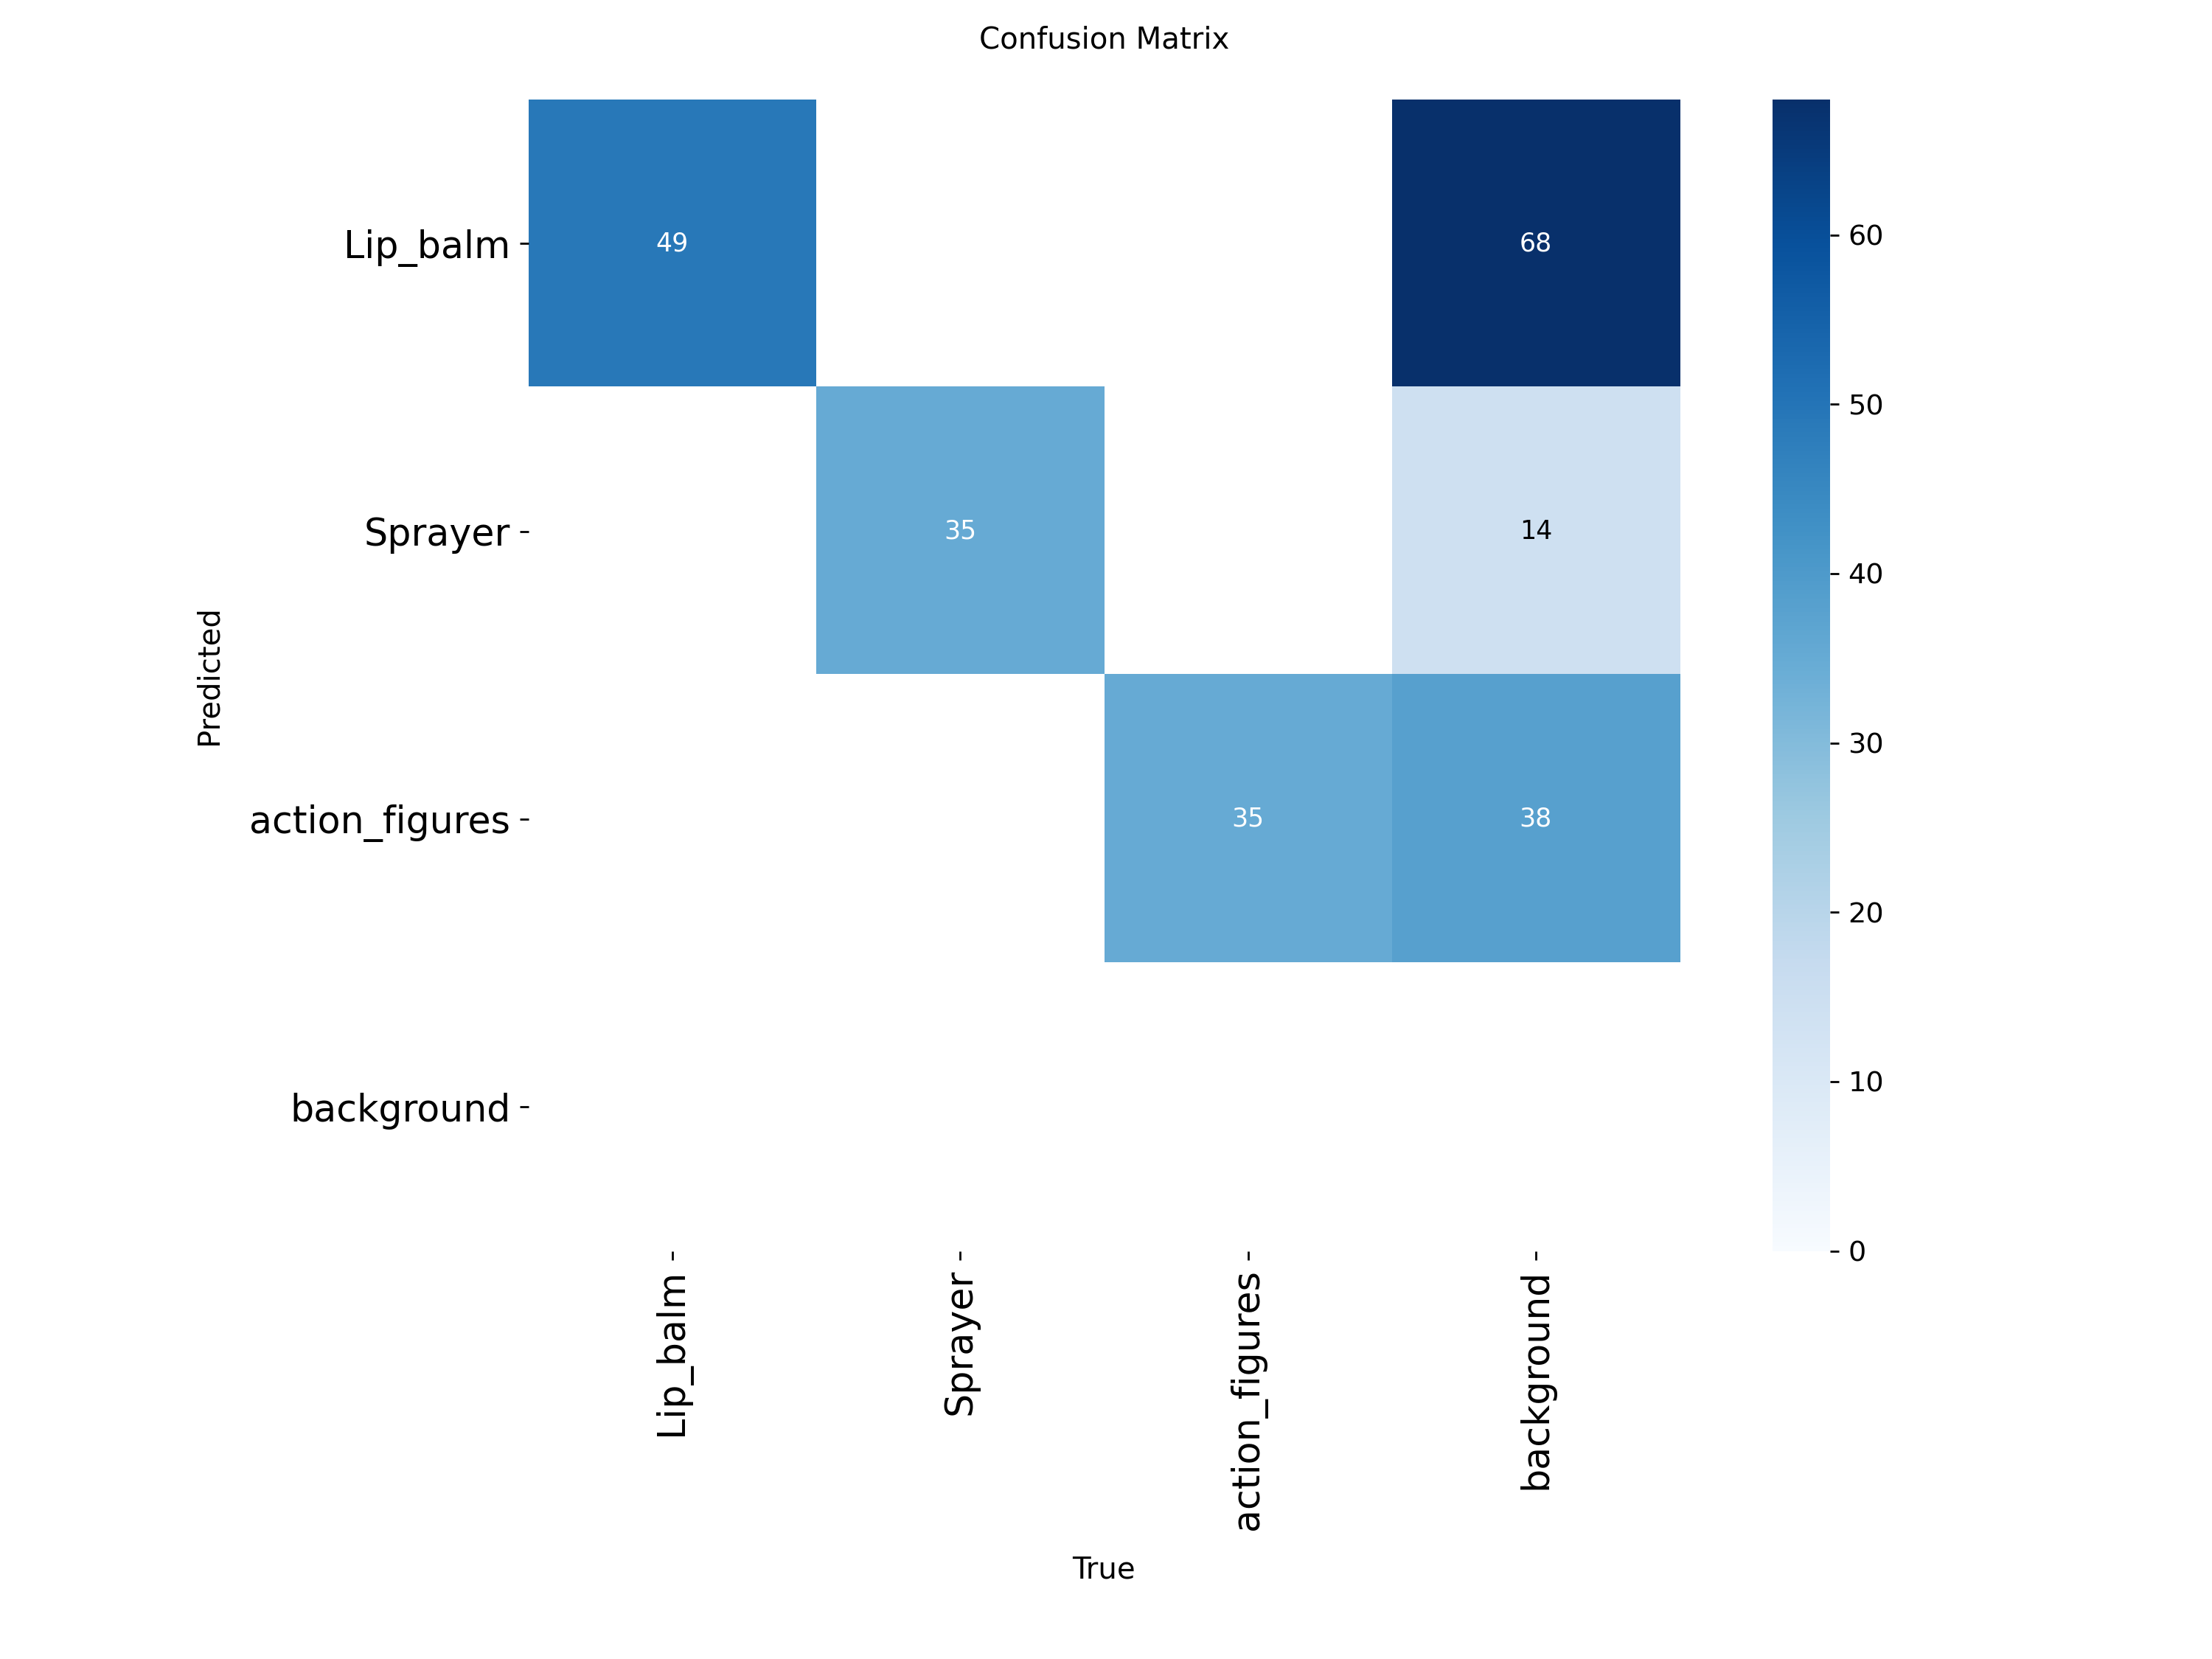

In [17]:
from IPython.display import Image, display
display(Image("/content/runs/detect/train-5/results.png"))
display(Image("/content/runs/detect/train-5/confusion_matrix.png"))

In [18]:
from google.colab import files
files.download("/content/runs/detect/train-5/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
model = YOLO("/content/runs/detect/train-5/weights/best.pt")

In [20]:
from google.colab import files
files.download("runs/detect/train-5/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
model = YOLO("runs/detect/train-5/weights/best.pt")

results = model.track(
    source="my_video.mp4",
    tracker="bytetrack.yaml",
    conf=0.4,
    save=True
)

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 492ms
Prepared 1 package in 59ms
Installed 1 package in 3ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 1.1s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/595) /content/my_video.mp4: 640x384 1 Lip_balm, 19.7ms
video 1/1 (frame 2/595) /con

In [1]:
model = YOLO("runs/detect/train-5/weights/best.pt")

results = model.track(
    source="my_video.mp4",
    tracker="bytetrack.yaml",
    conf=0.4,
    save=True
)

NameError: name 'YOLO' is not defined

In [ ]:
from ultralytics import YOLO

model = YOLO("runs/detect/train-5/weights/best.pt")
results = model.track(
    source="my_video.mp4", tracker="bytetrack.yaml", conf=0.4, save=True
)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/595) /content/my_video.mp4: 640x384 1 Lip_balm, 8.0ms
video 1/1 (frame 2/595) /content/my_video.mp4: 640x384 1 Lip_balm, 35.9ms
video 1/1 (frame 3/595) /content/my_video.mp4: 640x384 1 Lip_balm, 23.6ms
video 1/1 (frame 4/595) /content/my_video.mp4: 640x384 1 Lip_balm, 32.4ms
video 1/1 (frame 5/595) /content/my_video.mp4: 640x384 1 Lip_balm, 40.1ms
video 1/1 (frame 6/595) /content/my_video.mp4: 640x384 1 Lip_balm, 20.5ms
video 1/1 (frame

In [1]:
model = YOLO("runs/detect/train-5/weights/best.pt")

results = model.track(
    source="my_video.mp4",
    tracker="bytetrack.yaml",
    conf=0.4,
    save=True
)

NameError: name 'YOLO' is not defined

In [2]:
from ultralytics import YOLO

model = YOLO("runs/detect/train-5/weights/best.pt")
results = model.track(
    source="my_video.mp4", tracker="bytetrack.yaml", conf=0.4, save=True
)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/314) /content/my_video.mp4: 640x384 1 Lip_balm, 1 Sprayer, 1 action_figures, 6.4ms
video 1/1 (frame 2/314) /content/my_video.mp4: 640x384 1 Lip_balm, 1 Sprayer, 1 action_figures, 22.6ms
video 1/1 (frame 3/314) /content/my_video.mp4: 640x384 1 Lip_balm, 1 Sprayer, 1 action_figures, 30.0ms
video 1/1 (frame 4/314) /content/my_video.mp4: 640x384 1 Lip_balm, 1 Sprayer, 1 action_figures, 21.6ms
video 1/1 (frame 5/314) /content/my_video.mp4: 6

In [3]:
!ffmpeg -y -i runs/detect/track/my_video.avi -t 5 -c:v libx264 -pix_fmt yuv420p result.mp4

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [4]:
!ffmpeg -y -i runs/detect/track-3/my_video.avi -t 5 -c:v libx264 -pix_fmt yuv420p result.mp4

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [5]:
from google.colab import files
files.download("result.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
!ffmpeg -y -i my_video.avi -vf "scale=-2:720" -c:v libx264 -crf 28 -preset fast -an result_small.mp4
!ls -lh my_video.avi result_small.mp4

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [7]:
!ffmpeg -y -i /content/runs/detect/track-3/my_video.avi -t 5 -vf "scale=-2:720" -c:v libx264 -crf 28 -preset fast -pix_fmt yuv420p -an result_small.mp4
!ls -lh result_small.mp4

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [8]:
from google.colab import files
files.download("result_small.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>